# Confirmatory Counterfactual Causal Tracing (A100)

This notebook confirms the pilot's central mechanistic observation with a larger, balanced, frozen sample.

[实验设置与运行说明](../../../docs/experiment_notes/09_appendix_factor_routes/f55c3bb92b1a9e8e.md)


In [1]:
# Run this helper once. Every later code cell uses %%cell_progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 16 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 16 tracked cells.


## 1. Setup

The output is append-only and resumable at the pair level.


In [2]:
%%cell_progress 1/16 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/16 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/16 Install and verify the multimodal environment
import importlib
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])
cell_stage('Installing VisualTorque toolkit')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-e', str(TOOLKIT_ROOT)
])
SRC_ROOT = TOOLKIT_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))
importlib.invalidate_caches()

import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit:', visual_torque_toolkit.__file__)


Install and verify the multimodal environment:   6%|6         | 1/16 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/16 Verify A100 and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify A100 and Hugging Face access:  12%|#2        | 2/16 [00:00<?, ?cell/s]

NVIDIA A100-SXM4-40GB
CUDA memory (GB): 39.5
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/16 Lock the confirmatory causal-tracing protocol
cell_stage('Writing frozen hypotheses before pair selection')
import hashlib
import json
from datetime import datetime, timezone

MODEL_ID = 'Qwen/Qwen3.5-9B'
MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
MODEL_SLUG = 'Qwen__Qwen3.5-9B'
EXPECTED_SELECTED_LAYER = 13
SEED = 20260822

PAIRS_PER_EDIT = 32
EDIT_TYPES = ('add_unit', 'move_stack', 'redecompose', 'mirror')
PRIMARY_SCOPES = (
    'image_tokens', 'all_text_except_final', 'final_prompt_token',
)
TEXT_SEGMENT_SCOPES = (
    'intro_tokens', 'rule_tokens', 'question_tokens', 'options_tokens',
    'answer_instruction_tokens', 'separator_chat_tokens',
)
PRIMARY_LAYERS = (
    0, 8, 12, 13, 14, 15, 16, 17, 18,
    22, 23, 24, 25, 26, 27, 28, 31,
)
TEXT_LOCALIZATION_LAYERS = (
    14, 15, 16, 17, 18, 23, 24, 25, 26, 27, 28,
)
INFERENTIAL_LAYERS = tuple(
    layer for layer in PRIMARY_LAYERS if layer not in (0, 31)
)
PILOT_FINAL_TEST_LAYERS = {
    'add_unit': 23,
    'move_stack': 27,
    'redecompose': 23,
    'mirror': 27,
}
PATCH_CONDITION_BATCH_SIZE = 4
SMOKE_LOGPROB_TOLERANCE = 0.02
BOOTSTRAP_REPLICATES = 5000
NATURAL_EFFECT_EPS = 0.02
IMAGE_TOKEN_ID_OVERRIDE = None

MODEL_ROOT = PROJECT_ROOT / 'results' / MODEL_SLUG
DISCOVERY_ROOT = MODEL_ROOT / 'activation_discovery_v1'
PILOT_ROOT = MODEL_ROOT / 'natural_counterfactual_causal_tracing_v1'
OUTPUT_ROOT = MODEL_ROOT / 'counterfactual_causal_tracing_confirmatory_v1'
SHARD_DIR = OUTPUT_ROOT / 'pair_shards'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
SHARD_DIR.mkdir(parents=True, exist_ok=True)
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
PROTOCOL_LOCK_PATH = OUTPUT_ROOT / 'protocol_lock.json'

frozen_hypotheses = {
    'H1_early_visual_carrier': (
        'At layer 13, matched image-token recovery exceeds matched all-text recovery.'
    ),
    'H2_middle_text_handoff': (
        'At layer 16, matched all-text recovery exceeds matched image-token recovery.'
    ),
    'H3_pair_specific_text_path': (
        'At layer 16, matched all-text recovery exceeds unrelated same-source-outcome '
        'all-text recovery.'
    ),
    'H4_no_early_final_bottleneck': (
        'At layer 13, matched final-token mean recovery remains below 0.20.'
    ),
    'H5_prefinal_answer_commitment': (
        'At the edit-specific layer frozen from the pilot, matched final-token '
        'recovery exceeds the unrelated control with a pair-bootstrap 95% CI above '
        'zero (same-target for outcome-changing edits; same-outcome for redecompose).'
    ),
}
protocol_identity = {
    'schema_version': 'counterfactual-causal-tracing-confirmatory-1.0',
    'analysis_status': 'pilot_informed_frozen_confirmatory',
    'model_id': MODEL_ID,
    'pair_split': 'intervention_test',
    'pairs_per_edit': PAIRS_PER_EDIT,
    'edit_types': list(EDIT_TYPES),
    'pair_balance_fields': [
        'strategy_group', 'target_problem_type', 'outcome_transition',
        'delta_net_torque_sign',
    ],
    'option_policy': 'balanced_cycle_over_six_permutations_with_hashed_offset',
    'primary_layers': list(PRIMARY_LAYERS),
    'text_localization_layers': list(TEXT_LOCALIZATION_LAYERS),
    'inferential_layers_exclude_boundaries': list(INFERENTIAL_LAYERS),
    'pilot_frozen_final_test_layers': PILOT_FINAL_TEST_LAYERS,
    'primary_scopes': list(PRIMARY_SCOPES),
    'text_segment_scopes': list(TEXT_SEGMENT_SCOPES),
    'donor_controls': [
        'matched_source_for_all_primary_scopes',
        'unrelated_same_source_outcome_for_all_primary_scopes',
        'unrelated_same_target_outcome_for_all_primary_scopes_when_outcomes_differ',
    ],
    'frozen_hypotheses': frozen_hypotheses,
    'primary_metric': (
        'projection recovery in centered left/right/balanced semantic-logprob space'
    ),
    'bootstrap_unit': 'counterfactual_pair',
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'natural_effect_epsilon': NATURAL_EFFECT_EPS,
    'boundary_rule': (
        'layer 0 and layer 31 are descriptive implementation ceilings only; '
        'neither may support a mechanistic claim'
    ),
    'redecompose_analysis': [
        'prediction invariance', 'both-endpoint accuracy',
        'gold-candidate confidence change', 'semantic-output effect norm',
    ],
    'patch_condition_batch_size': PATCH_CONDITION_BATCH_SIZE,
    'smoke_logprob_tolerance': SMOKE_LOGPROB_TOLERANCE,
    'image_token_id_override': IMAGE_TOKEN_ID_OVERRIDE,
    'seed': SEED,
    'interpretation_limit': (
        'Token-group activation patching can localize a causal information route, '
        'but does not yet identify a unique attention head, MLP, scalar torque code, '
        'or complete mediation mechanism.'
    ),
}

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == protocol_identity, (
        'Existing confirmatory protocol differs. Use a new versioned output directory.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })
print('Model:', MODEL_ID)
print('Planned pairs:', PAIRS_PER_EDIT * len(EDIT_TYPES))
print('Primary layers:', PRIMARY_LAYERS)
print('Text-localization layers:', TEXT_LOCALIZATION_LAYERS)
print('Protocol:', PROTOCOL_LOCK_PATH)


Lock the confirmatory causal-tracing protocol:  19%|#8        | 3/16 [00:00<?, ?cell/s]

Model: Qwen/Qwen3.5-9B
Planned pairs: 128
Primary layers: (0, 8, 12, 13, 14, 15, 16, 17, 18, 22, 23, 24, 25, 26, 27, 28, 31)
Text-localization layers: (14, 15, 16, 17, 18, 23, 24, 25, 26, 27, 28)
Protocol: /content/drive/MyDrive/VisualTorque/results/Qwen__Qwen3.5-9B/counterfactual_causal_tracing_confirmatory_v1/protocol_lock.json


In [6]:
%%cell_progress 5/16 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  25%|##5       | 4/16 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


## 2. Frozen pair selection and model loading

Pair sampling uses no model output.


In [7]:
%%cell_progress 6/16 Select 128 balanced confirmatory pairs
cell_stage('Loading scenes, intervention pairs, and examples')
from collections import Counter, defaultdict

from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

scene_records = read_jsonl(DATASET_DIR / 'scenes.jsonl')
pair_records = read_jsonl(DATASET_DIR / 'counterfactual_pairs.jsonl')
scene_by_id = {str(row['scene_id']): row for row in scene_records}

discovery_config_path = DISCOVERY_ROOT / 'capture_config.json'
discovery_selection_path = (
    DISCOVERY_ROOT / 'probe_results' / 'discovery_selection.json'
)
pilot_summary_path = PILOT_ROOT / 'analysis' / 'decision_summary.json'
for required in (
    discovery_config_path, discovery_selection_path, pilot_summary_path,
):
    assert required.is_file(), f'Missing prerequisite: {required}'
discovery_config = json.loads(
    discovery_config_path.read_text(encoding='utf-8')
)
discovery_identity = discovery_config['identity']
MODEL_REVISION = str(discovery_identity['resolved_revision'])
discovery_selection = json.loads(
    discovery_selection_path.read_text(encoding='utf-8')
)
SELECTED_LAYER_INDEX = int(
    discovery_selection['candidate_net_torque_layer']['layer_index']
)
assert SELECTED_LAYER_INDEX == EXPECTED_SELECTED_LAYER

example_config = BehaviorRunConfig(
    dataset_dir=DATASET_DIR,
    output_dir=Path('/content/unused_confirmatory_tracing'),
    model_id=MODEL_ID,
    model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE,),
    question_kinds=('outcome',),
    splits=('probe_train', 'probe_dev', 'probe_test'),
    batch_size=1,
    generation_every=0,
    seed=SEED,
)
all_examples = tuple(load_behavior_examples(example_config))
example_by_scene_variant = {
    (str(example.scene_id), str(example.variant)): example
    for example in all_examples
}
assert len(example_by_scene_variant) == 6 * len(scene_records)

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value}'.encode('utf-8')).hexdigest()

def strategy_group(problem_type):
    name = str(problem_type)
    if 'conflict' in name:
        return 'conflict'
    if 'compatible' in name:
        return 'compatible'
    if name == 'multi_stack':
        return 'multi_stack'
    if name in ('weight', 'distance'):
        return 'single_cue'
    if name == 'balance':
        return 'balance'
    return 'other'

def pair_stratum(pair):
    target = scene_by_id[str(pair['target_scene_id'])]
    return (
        strategy_group(target['problem_type']),
        str(target['problem_type']),
        f"{pair['target_outcome']}->{pair['source_outcome']}",
        int(np.sign(int(pair['delta_net_torque']))),
    )

def round_robin_strata(rows, count):
    groups = defaultdict(list)
    for row in rows:
        groups[pair_stratum(row)].append(row)
    for values in groups.values():
        values.sort(key=lambda row: stable_key(row['pair_id']))
    keys = sorted(groups, key=lambda key: stable_key('stratum:' + repr(key)))
    cursor = {key: 0 for key in keys}
    selected = []
    while len(selected) < min(count, len(rows)):
        changed = False
        for key in keys:
            index = cursor[key]
            if index < len(groups[key]) and len(selected) < count:
                selected.append(groups[key][index])
                cursor[key] += 1
                changed = True
        if not changed:
            break
    return selected

selected_pairs = []
for edit_type in EDIT_TYPES:
    candidates = [
        row for row in pair_records
        if row['split'] == 'intervention_test'
        and row['edit_type'] == edit_type
    ]
    if edit_type == 'redecompose':
        candidates = [
            row for row in candidates
            if row['source_outcome'] == row['target_outcome']
            and int(row['delta_net_torque']) == 0
        ]
    else:
        candidates = [
            row for row in candidates
            if row['source_outcome'] != row['target_outcome']
        ]
    chosen = round_robin_strata(candidates, PAIRS_PER_EDIT)
    assert len(chosen) == PAIRS_PER_EDIT, (edit_type, len(chosen))
    selected_pairs.extend(chosen)

def select_control_scene(
    reference_scene_id, desired_outcome, excluded, salt,
):
    reference = scene_by_id[str(reference_scene_id)]
    candidates = []
    for scene in scene_records:
        scene_id = str(scene['scene_id'])
        if scene_id in excluded:
            continue
        if str(scene['derived']['outcome']) != str(desired_outcome):
            continue
        same_problem = int(scene['problem_type'] == reference['problem_type'])
        same_strategy = int(
            strategy_group(scene['problem_type'])
            == strategy_group(reference['problem_type'])
        )
        torque_gap = abs(
            int(scene['derived']['net_torque'])
            - int(reference['derived']['net_torque'])
        )
        unit_gap = abs(
            int(scene['derived']['left_units'])
            + int(scene['derived']['right_units'])
            - int(reference['derived']['left_units'])
            - int(reference['derived']['right_units'])
        )
        candidates.append((
            -same_problem, -same_strategy, torque_gap, unit_gap,
            stable_key(f'control:{salt}:{reference_scene_id}:{scene_id}'),
            scene_id,
        ))
    assert candidates, (reference_scene_id, desired_outcome)
    candidates.sort()
    return candidates[0][-1]

pair_manifest = []
variant_counters = defaultdict(int)
for pair in sorted(selected_pairs, key=lambda row: row['pair_id']):
    edit_type = str(pair['edit_type'])
    offset = int(stable_key('variant-offset:' + edit_type)[:8], 16) % 6
    variant_index = (offset + variant_counters[edit_type]) % 6
    variant_counters[edit_type] += 1
    variant = f'permutation_{variant_index}'
    source_id = str(pair['source_scene_id'])
    target_id = str(pair['target_scene_id'])
    excluded = {source_id, target_id}
    same_source_id = select_control_scene(
        source_id, pair['source_outcome'], excluded, 'same-source'
    )
    excluded.add(same_source_id)
    same_target_id = None
    if pair['source_outcome'] != pair['target_outcome']:
        same_target_id = select_control_scene(
            target_id, pair['target_outcome'], excluded, 'same-target'
        )
    source_scene = scene_by_id[source_id]
    target_scene = scene_by_id[target_id]
    pair_manifest.append({
        'pair_id': str(pair['pair_id']),
        'edit_type': edit_type,
        'equivalence_key': str(pair['equivalence_key']),
        'changed_stack_ids': list(pair['changed_stack_ids']),
        'delta_net_torque': int(pair['delta_net_torque']),
        'source_scene_id': source_id,
        'target_scene_id': target_id,
        'source_outcome': str(pair['source_outcome']),
        'target_outcome': str(pair['target_outcome']),
        'source_problem_type': str(source_scene['problem_type']),
        'target_problem_type': str(target_scene['problem_type']),
        'strategy_group': strategy_group(target_scene['problem_type']),
        'outcome_transition': (
            f"{pair['target_outcome']}->{pair['source_outcome']}"
        ),
        'source_net_torque': int(source_scene['derived']['net_torque']),
        'target_net_torque': int(target_scene['derived']['net_torque']),
        'source_left_torque': int(source_scene['derived']['left_torque']),
        'source_right_torque': int(source_scene['derived']['right_torque']),
        'target_left_torque': int(target_scene['derived']['left_torque']),
        'target_right_torque': int(target_scene['derived']['right_torque']),
        'source_total_units': int(
            source_scene['derived']['left_units']
            + source_scene['derived']['right_units']
        ),
        'target_total_units': int(
            target_scene['derived']['left_units']
            + target_scene['derived']['right_units']
        ),
        'variant': variant,
        'same_source_outcome_control_scene_id': same_source_id,
        'same_target_outcome_control_scene_id': same_target_id,
    })

manifest_path = OUTPUT_ROOT / 'pair_manifest.jsonl'
temporary_manifest = manifest_path.with_suffix('.jsonl.tmp')
with temporary_manifest.open('w', encoding='utf-8') as handle:
    for row in pair_manifest:
        handle.write(json.dumps(row, sort_keys=True) + '\n')
temporary_manifest.replace(manifest_path)

selection_table = pd.DataFrame(pair_manifest)
assert selection_table['pair_id'].nunique() == len(pair_manifest)
assert set(selection_table.groupby('edit_type').size()) == {PAIRS_PER_EDIT}
print('Selected pairs:', len(pair_manifest))
display(pd.crosstab(
    selection_table['edit_type'], selection_table['strategy_group']
))
print('Variants by edit:')
display(pd.crosstab(selection_table['edit_type'], selection_table['variant']))
print('Outcome transitions:')
display(pd.crosstab(
    selection_table['edit_type'], selection_table['outcome_transition']
))


Select 128 balanced confirmatory pairs:  31%|###1      | 5/16 [00:00<?, ?cell/s]

Selected pairs: 128


strategy_group,balance,compatible,conflict,multi_stack,single_cue
edit_type,,,,,
add_unit,3,0,16,3,10
mirror,0,5,8,9,10
move_stack,2,0,15,7,8
redecompose,2,4,11,6,9


Variants by edit:


variant,permutation_0,permutation_1,permutation_2,permutation_3,permutation_4,permutation_5
edit_type,,,,,,
add_unit,5,5,5,5,6,6
mirror,5,6,6,5,5,5
move_stack,5,6,6,5,5,5
redecompose,5,5,5,5,6,6


Outcome transitions:


outcome_transition,balanced->balanced,balanced->left,balanced->right,left->balanced,left->left,left->right,right->balanced,right->left,right->right
edit_type,,,,,,,,,
add_unit,0,3,4,7,0,6,6,6,0
mirror,0,0,0,0,0,8,0,24,0
move_stack,0,4,4,6,0,6,6,6,0
redecompose,6,0,0,0,14,0,0,0,12


In [8]:
%%cell_progress 7/16 Load the pinned Qwen model and decoder layers
cell_stage('Loading processor and pinned model weights')
adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID,
    revision=MODEL_REVISION,
    dtype=MODEL_DTYPE,
    device_map=DEVICE_MAP,
)
display(adapter.metadata)

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = [
        discovery_identity.get('layer_path'),
        'model.language_model.layers',
        'model.text_model.layers',
        'language_model.model.layers',
        'language_model.layers',
        'model.model.layers',
        'model.layers',
    ]
    failures = []
    for path in candidates:
        if not path:
            continue
        try:
            layers = resolve_module_path(model, path)
        except (AttributeError, KeyError) as exc:
            failures.append(f'{path}: {exc}')
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
        failures.append(f'{path}: {type(layers).__name__}')
    raise RuntimeError('Could not locate decoder layers:\n' + '\n'.join(failures))

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == 32, len(DECODER_LAYERS)
assert max(PRIMARY_LAYERS) < len(DECODER_LAYERS)
resolved_now = adapter.metadata.get('resolved_revision')
if resolved_now is not None:
    assert str(resolved_now) == MODEL_REVISION
print('Layer path:', LAYER_PATH)
print('Decoder layers:', len(DECODER_LAYERS))
print('Selected representation layer:', SELECTED_LAYER_INDEX)
print('Inferential layers:', INFERENTIAL_LAYERS)


Load the pinned Qwen model and decoder layers:  38%|###7      | 6/16 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/760 [00:00<?, ?it/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-9B',
 'requested_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'resolved_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 9409813744,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Decoder layers: 32
Selected representation layer: 13
Inferential layers: (8, 12, 13, 14, 15, 16, 17, 18, 22, 23, 24, 25, 26, 27, 28)


## 3. Batched natural activation patching and token segmentation

Conditions for the same target image are scored together in batches of up to four.


In [9]:
%%cell_progress 8/16 Define preparation, masks, and prompt segments
cell_stage('Defining aligned multimodal preparation')
import math

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(
        output.last_hidden_state
    ):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported decoder output: {type(output).__name__}')
    if hidden.ndim != 3:
        raise ValueError(f'Expected [batch, sequence, hidden], got {hidden.shape}')
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(
        'Decoder output object is not safely replaceable: '
        + type(output).__name__
    )

def prepare_examples(examples):
    examples = tuple(examples)
    assert examples
    first_plan = adapter._candidate_plan(examples[0])
    if first_plan is None:
        raise RuntimeError('Confirmatory tracing requires single-token labels.')
    fixed_prefix, token_by_label = first_plan
    for example in examples[1:]:
        assert adapter._candidate_plan(example) == first_plan
        assert example.labels == examples[0].labels
    inputs = adapter._append_text_prefix(
        adapter._to_device(
            adapter._template(
                [example.messages() for example in examples],
                add_generation_prompt=True,
            )
        ),
        fixed_prefix,
    )
    return {
        'examples': examples,
        'inputs': inputs,
        'token_by_label': token_by_label,
    }

def flatten_integer_values(value):
    if value is None:
        return []
    if isinstance(value, (int, np.integer)):
        return [int(value)]
    if isinstance(value, (tuple, list, set)):
        result = []
        for item in value:
            result.extend(flatten_integer_values(item))
        return result
    return []

def locate_subsequence(sequence, subsequence):
    matches = []
    width = len(subsequence)
    for start in range(len(sequence) - width + 1):
        if sequence[start:start + width] == subsequence:
            matches.append(start)
    if len(matches) != 1:
        raise RuntimeError(
            f'Expected one prompt-token subsequence, found {len(matches)}.'
        )
    return matches[0]

def discover_token_masks(prepared):
    assert len(prepared['examples']) == 1
    example = prepared['examples'][0]
    inputs = prepared['inputs']
    input_ids = inputs['input_ids'][0].detach().cpu()
    attention = inputs.get('attention_mask')
    valid = (
        attention[0].detach().cpu().bool()
        if attention is not None
        else torch.ones_like(input_ids, dtype=torch.bool)
    )
    tokenizer = getattr(adapter.processor, 'tokenizer', adapter.processor)
    tokens = tokenizer.convert_ids_to_tokens(input_ids.tolist())
    candidate_ids = set(flatten_integer_values(IMAGE_TOKEN_ID_OVERRIDE))
    for owner in (
        adapter.processor, adapter.model, getattr(adapter.model, 'config', None),
    ):
        if owner is None:
            continue
        for name in (
            'image_token_id', 'image_token_ids', 'image_token_index',
            'vision_token_id', 'vision_token_ids',
        ):
            candidate_ids.update(flatten_integer_values(getattr(owner, name, None)))
    for token_id, token_text in zip(input_ids.tolist(), tokens):
        lower = str(token_text).lower()
        if any(marker in lower for marker in ('image', 'vision', '<img', 'img>')):
            candidate_ids.add(int(token_id))
    image = torch.tensor(
        [int(token_id) in candidate_ids for token_id in input_ids.tolist()],
        dtype=torch.bool,
    ) & valid
    if not bool(image.any()):
        raise RuntimeError(
            'Image tokens were not detected. Set IMAGE_TOKEN_ID_OVERRIDE and use '
            'a new versioned output directory.'
        )
    final_index = int(torch.where(valid)[0][-1])
    final = torch.zeros_like(valid)
    final[final_index] = True
    all_text = valid & ~image & ~final

    prompt_encoding = tokenizer(
        example.prompt,
        add_special_tokens=False,
        return_offsets_mapping=True,
    )
    prompt_ids = list(prompt_encoding['input_ids'])
    offsets = list(prompt_encoding['offset_mapping'])
    prompt_start = locate_subsequence(input_ids.tolist(), prompt_ids)
    section_names = (
        'intro_tokens', 'rule_tokens', 'question_tokens',
        'options_tokens', 'answer_instruction_tokens',
    )
    sections = example.prompt.split('\n\n')
    assert len(sections) == len(section_names), sections
    masks = {
        'valid_tokens': valid,
        'image_tokens': image,
        'all_text_except_final': all_text,
        'final_prompt_token': final,
    }
    cursor = 0
    section_spans = []
    for name, section in zip(section_names, sections):
        start_character = example.prompt.find(section, cursor)
        assert start_character >= 0
        end_character = start_character + len(section)
        cursor = end_character
        section_spans.append((name, start_character, end_character))
        masks[name] = torch.zeros_like(valid)
    # Assign each prompt token to exactly one section by maximum character
    # overlap. Newline separators and chat-template tokens remain in the
    # separator/chat group. This avoids double assignment if a BPE token
    # happens to straddle a section boundary.
    for offset_index, (token_start, token_end) in enumerate(offsets):
        overlaps = []
        for name, start_character, end_character in section_spans:
            overlap = max(
                0,
                min(token_end, end_character)
                - max(token_start, start_character),
            )
            overlaps.append((overlap, name))
        best_overlap, best_name = max(overlaps)
        full_index = prompt_start + offset_index
        if best_overlap > 0 and bool(all_text[full_index]):
            masks[best_name][full_index] = True
    for name in section_names:
        assert bool(masks[name].any()), name
    covered = torch.zeros_like(valid)
    for name in section_names:
        covered |= masks[name]
    masks['separator_chat_tokens'] = all_text & ~covered
    assert bool(masks['separator_chat_tokens'].any())
    segment_union = torch.zeros_like(valid)
    for name in TEXT_SEGMENT_SCOPES:
        assert not bool((segment_union & masks[name]).any()), name
        segment_union |= masks[name]
    assert torch.equal(segment_union, all_text)
    masks['tokens'] = tokens
    masks['candidate_image_token_ids'] = sorted(candidate_ids)
    return masks

def assert_aligned(donor_prepared, target_prepared):
    for key in ('input_ids', 'attention_mask'):
        donor_value = donor_prepared['inputs'].get(key)
        target_value = target_prepared['inputs'].get(key)
        assert donor_value is not None and target_value is not None
        assert torch.equal(donor_value, target_value), key
    donor_masks = discover_token_masks(donor_prepared)
    target_masks = discover_token_masks(target_prepared)
    for scope in (
        ('valid_tokens',) + PRIMARY_SCOPES + TEXT_SEGMENT_SCOPES
    ):
        assert torch.equal(donor_masks[scope], target_masks[scope]), scope
    return target_masks

print('Preparation and exact text segmentation ready.')


Define preparation, masks, and prompt segments:  44%|####3     | 7/16 [00:00<?, ?cell/s]

Preparation and exact text segmentation ready.


In [10]:
%%cell_progress 9/16 Define batched capture and activation patching
cell_stage('Defining semantic scoring and batched hooks')

def semantic_records(prepared, logits):
    next_logprobs = torch.log_softmax(logits[:, -1, :].float(), dim=-1)
    records = []
    for row_index, example in enumerate(prepared['examples']):
        label_scores = {
            label: float(next_logprobs[
                row_index, prepared['token_by_label'][label]
            ].detach().cpu())
            for label in example.labels
        }
        semantic_scores = {
            str(example.label_to_semantic[label]): label_scores[label]
            for label in example.labels
        }
        maximum = max(semantic_scores.values())
        weights = {
            key: math.exp(value - maximum)
            for key, value in semantic_scores.items()
        }
        normalizer = sum(weights.values())
        probabilities = {
            key: value / normalizer for key, value in weights.items()
        }
        predicted = max(sorted(semantic_scores), key=semantic_scores.get)
        records.append({
            'scene_id': str(example.scene_id),
            'example_id': str(example.example_id),
            'variant': str(example.variant),
            'gold_outcome': str(example.gold_semantic),
            'predicted_semantic': predicted,
            'correct': predicted == str(example.gold_semantic),
            **{
                f'logprob_{name}': semantic_scores[name]
                for name in ('left', 'right', 'balanced')
            },
            **{
                f'candidate_prob_{name}': probabilities[name]
                for name in ('left', 'right', 'balanced')
            },
        })
    return records

def forward_capture(prepared):
    assert len(prepared['examples']) == 1
    captured = {}
    handles = []
    for layer_index in PRIMARY_LAYERS:
        def hook(_module, _inputs, output, layer_index=layer_index):
            captured[layer_index] = (
                output_hidden_tensor(output)[0].detach().cpu().clone()
            )
        handles.append(DECODER_LAYERS[layer_index].register_forward_hook(hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    assert set(captured) == set(PRIMARY_LAYERS)
    return semantic_records(prepared, output.logits)[0], captured

def forward_patch_chunk(target_prepared, conditions):
    assert len(target_prepared['examples']) == len(conditions)
    layer_indices = {int(condition['layer_index']) for condition in conditions}
    assert len(layer_indices) == 1
    layer_index = next(iter(layer_indices))
    donor_batch = torch.stack([
        condition['donor_hidden'] for condition in conditions
    ], dim=0)
    mask_batch = torch.stack([
        condition['patch_mask'] for condition in conditions
    ], dim=0)
    audit = {}

    def patch_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        donors = donor_batch.to(device=hidden.device, dtype=hidden.dtype)
        masks = mask_batch.to(device=hidden.device)
        assert hidden.shape == donors.shape
        assert masks.shape == hidden.shape[:2]
        modified = hidden.clone()
        modified[masks] = donors[masks]
        audit['counts'] = masks.sum(dim=1).detach().cpu().tolist()
        return replace_output_hidden(output, modified)

    handle = DECODER_LAYERS[layer_index].register_forward_hook(patch_hook)
    try:
        with torch.inference_mode():
            output = adapter.model(**target_prepared['inputs'], use_cache=False)
    finally:
        handle.remove()
    scores = semantic_records(target_prepared, output.logits)
    for record, condition, count in zip(scores, conditions, audit['counts']):
        record.update({
            key: value for key, value in condition.items()
            if key != 'donor_hidden' and key != 'patch_mask'
        })
        record['patched_tokens'] = int(count)
    return scores

def chunked(values, size):
    for start in range(0, len(values), size):
        yield values[start:start + size]

def score_condition_chunks(target_example, prepared_cache, conditions):
    records = []

    def score_with_fallback(condition_chunk):
        size = len(condition_chunk)
        try:
            prepared = prepared_cache.get(size)
            if prepared is None:
                prepared = prepare_examples([target_example] * size)
                prepared_cache[size] = prepared
            return forward_patch_chunk(prepared, condition_chunk)
        except torch.cuda.OutOfMemoryError:
            prepared_cache.pop(size, None)
            try:
                del prepared
            except UnboundLocalError:
                pass
            torch.cuda.empty_cache()
            if size == 1:
                raise
            midpoint = size // 2
            return (
                score_with_fallback(condition_chunk[:midpoint])
                + score_with_fallback(condition_chunk[midpoint:])
            )

    for condition_chunk in chunked(
        conditions, PATCH_CONDITION_BATCH_SIZE
    ):
        records.extend(score_with_fallback(condition_chunk))
    return records

print('Batched scorer ready; OOM fallback enabled.')


Define batched capture and activation patching:  50%|#####     | 8/16 [00:00<?, ?cell/s]

Batched scorer ready; OOM fallback enabled.


In [11]:
%%cell_progress 10/16 Run mandatory segmentation, parity, and batch smoke tests
cell_stage('Preparing the first confirmatory pair')
smoke_pair = pair_manifest[0]
variant = smoke_pair['variant']
source_example = example_by_scene_variant[
    (smoke_pair['source_scene_id'], variant)
]
target_example = example_by_scene_variant[
    (smoke_pair['target_scene_id'], variant)
]
source_prepared = prepare_examples([source_example])
target_prepared = prepare_examples([target_example])
masks = assert_aligned(source_prepared, target_prepared)

cell_stage('Capturing natural source and target states')
source_score, source_hidden = forward_capture(source_prepared)
target_score, target_hidden = forward_capture(target_prepared)
smoke_layer = SELECTED_LAYER_INDEX
smoke_conditions = [
    {
        'condition': 'smoke_self_all_tokens',
        'donor_type': 'self_target',
        'scope': 'valid_tokens',
        'layer_index': smoke_layer,
        'donor_scene_id': smoke_pair['target_scene_id'],
        'donor_hidden': target_hidden[smoke_layer],
        'patch_mask': masks['valid_tokens'],
    },
    {
        'condition': 'smoke_source_all_tokens',
        'donor_type': 'matched_source',
        'scope': 'valid_tokens',
        'layer_index': smoke_layer,
        'donor_scene_id': smoke_pair['source_scene_id'],
        'donor_hidden': source_hidden[smoke_layer],
        'patch_mask': masks['valid_tokens'],
    },
]
smoke_batch = prepare_examples([target_example] * 2)
smoke_scores = forward_patch_chunk(smoke_batch, smoke_conditions)
score_names = ('logprob_left', 'logprob_right', 'logprob_balanced')
self_error = max(
    abs(smoke_scores[0][name] - target_score[name]) for name in score_names
)
source_error = max(
    abs(smoke_scores[1][name] - source_score[name]) for name in score_names
)
assert self_error < SMOKE_LOGPROB_TOLERANCE, self_error
assert source_error < SMOKE_LOGPROB_TOLERANCE, source_error

cell_stage('Checking repeated-target batch equivalence')
repeated = prepare_examples([target_example] * PATCH_CONDITION_BATCH_SIZE)
with torch.inference_mode():
    repeated_output = adapter.model(**repeated['inputs'], use_cache=False)
repeated_scores = semantic_records(repeated, repeated_output.logits)
batch_error = max(
    abs(record[name] - target_score[name])
    for record in repeated_scores for name in score_names
)
assert batch_error < SMOKE_LOGPROB_TOLERANCE, batch_error

mask_counts = {
    name: int(masks[name].sum())
    for name in (
        ('valid_tokens',) + PRIMARY_SCOPES + TEXT_SEGMENT_SCOPES
    )
}
assert sum(mask_counts[name] for name in TEXT_SEGMENT_SCOPES) == (
    mask_counts['all_text_except_final']
)
print('Token counts:', mask_counts)
print('Detected image token IDs:', masks['candidate_image_token_ids'])
print('Self-patch error:', self_error)
print('All-token source ceiling error:', source_error)
print('Repeated-target batch error:', batch_error)
print('Mandatory smoke tests passed.')
del source_hidden, target_hidden, repeated, repeated_output
torch.cuda.empty_cache()


Run mandatory segmentation, parity, and batch smoke tests:  56%|#####6    | 9/16 [00:00<?, ?cell/s]

Token counts: {'valid_tokens': 530, 'image_tokens': 394, 'all_text_except_final': 135, 'final_prompt_token': 1, 'intro_tokens': 12, 'rule_tokens': 48, 'question_tokens': 9, 'options_tokens': 25, 'answer_instruction_tokens': 26, 'separator_chat_tokens': 15}
Detected image token IDs: [248053, 248054, 248056]
Self-patch error: 4.208087921142578e-05
All-token source ceiling error: 0.00019502639770507812
Repeated-target batch error: 0.00015407800674438477
Mandatory smoke tests passed.


In [12]:
%%cell_progress 11/16 Freeze identity and capture or resume 128 pairs
cell_stage('Hashing confirmatory inputs and reading completed shards')

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

outcome_changing_count = sum(
    row['source_outcome'] != row['target_outcome']
    for row in pair_manifest
)
primary_records = (
    len(pair_manifest) * len(PRIMARY_LAYERS) * len(PRIMARY_SCOPES) * 2
    + outcome_changing_count * len(PRIMARY_LAYERS) * len(PRIMARY_SCOPES)
)
localization_records = (
    len(pair_manifest) * len(TEXT_LOCALIZATION_LAYERS)
    * len(TEXT_SEGMENT_SCOPES)
)
EXPECTED_PATCH_RECORDS = primary_records + localization_records
capture_identity = {
    'schema_version': 'counterfactual-causal-tracing-confirmatory-capture-1.0',
    'model_id': MODEL_ID,
    'resolved_revision': MODEL_REVISION,
    'dtype': MODEL_DTYPE,
    'dataset_fingerprint': example_config.dataset_fingerprint(),
    'protocol_lock_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'pair_manifest_sha256': sha256_file(manifest_path),
    'discovery_capture_sha256': sha256_file(discovery_config_path),
    'discovery_selection_sha256': sha256_file(discovery_selection_path),
    'pilot_summary_sha256': sha256_file(pilot_summary_path),
    'layer_path': LAYER_PATH,
    'decoder_layer_count': len(DECODER_LAYERS),
    'primary_layers': list(PRIMARY_LAYERS),
    'text_localization_layers': list(TEXT_LOCALIZATION_LAYERS),
    'mask_counts': mask_counts,
    'detected_image_token_ids': masks['candidate_image_token_ids'],
    'expected_pairs': len(pair_manifest),
    'expected_patch_records': EXPECTED_PATCH_RECORDS,
    'patch_condition_batch_size': PATCH_CONDITION_BATCH_SIZE,
    'seed': SEED,
}
capture_config_path = OUTPUT_ROOT / 'capture_config.json'
if capture_config_path.is_file():
    previous = json.loads(capture_config_path.read_text(encoding='utf-8'))
    assert previous.get('identity') == capture_identity, (
        'Existing capture identity differs. Use a new output version.'
    )
else:
    write_json_atomic(capture_config_path, {
        'identity': capture_identity,
        'adapter_metadata': adapter.metadata,
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
    })
CAPTURE_SHA256 = sha256_file(capture_config_path)

completed_pair_ids = set()
completed_records = 0
for path in sorted(SHARD_DIR.glob('shard_pair_*.json')):
    payload = json.loads(path.read_text(encoding='utf-8'))
    assert payload['capture_identity_sha256'] == CAPTURE_SHA256
    pair_id = str(payload['pair']['pair_id'])
    if pair_id in completed_pair_ids:
        raise RuntimeError(f'Duplicate pair shard: {pair_id}')
    completed_pair_ids.add(pair_id)
    completed_records += len(payload['patch_records'])
expected_pair_ids = {row['pair_id'] for row in pair_manifest}
assert completed_pair_ids <= expected_pair_ids
print('Completed pairs:', len(completed_pair_ids))

progress = tqdm(
    total=EXPECTED_PATCH_RECORDS,
    initial=completed_records,
    desc='Confirmatory patch records', unit='condition', dynamic_ncols=True,
)
for pair_index, pair in enumerate(pair_manifest):
    pair_id = pair['pair_id']
    if pair_id in completed_pair_ids:
        continue
    progress.set_postfix_str(
        f"{pair['edit_type']} | {pair_id}", refresh=True
    )
    variant = pair['variant']
    source_example = example_by_scene_variant[
        (pair['source_scene_id'], variant)
    ]
    target_example = example_by_scene_variant[
        (pair['target_scene_id'], variant)
    ]
    same_source_example = example_by_scene_variant[
        (pair['same_source_outcome_control_scene_id'], variant)
    ]
    same_target_example = None
    if pair['same_target_outcome_control_scene_id'] is not None:
        same_target_example = example_by_scene_variant[
            (pair['same_target_outcome_control_scene_id'], variant)
        ]

    source_prepared = prepare_examples([source_example])
    target_prepared = prepare_examples([target_example])
    same_source_prepared = prepare_examples([same_source_example])
    same_target_prepared = (
        prepare_examples([same_target_example])
        if same_target_example is not None else None
    )
    masks = assert_aligned(source_prepared, target_prepared)
    assert_aligned(same_source_prepared, target_prepared)
    if same_target_prepared is not None:
        assert_aligned(same_target_prepared, target_prepared)

    source_score, source_hidden = forward_capture(source_prepared)
    target_score, target_hidden = forward_capture(target_prepared)
    same_source_score, same_source_hidden = forward_capture(
        same_source_prepared
    )
    same_target_score = None
    same_target_hidden = None
    if same_target_prepared is not None:
        same_target_score, same_target_hidden = forward_capture(
            same_target_prepared
        )

    prepared_cache = {1: target_prepared}
    patch_records = []
    for layer_index in PRIMARY_LAYERS:
        conditions = []
        donor_specs = [
            (
                'matched_source', pair['source_scene_id'], source_hidden,
            ),
            (
                'unrelated_same_source_outcome',
                pair['same_source_outcome_control_scene_id'],
                same_source_hidden,
            ),
        ]
        if same_target_hidden is not None:
            donor_specs.append((
                'unrelated_same_target_outcome',
                pair['same_target_outcome_control_scene_id'],
                same_target_hidden,
            ))
        for donor_type, donor_scene_id, donor_layers in donor_specs:
            for scope in PRIMARY_SCOPES:
                conditions.append({
                    'condition': f'{donor_type}__{scope}',
                    'donor_type': donor_type,
                    'scope': scope,
                    'analysis_family': 'primary_scope',
                    'layer_index': int(layer_index),
                    'donor_scene_id': donor_scene_id,
                    'donor_hidden': donor_layers[layer_index],
                    'patch_mask': masks[scope],
                })
        records = score_condition_chunks(
            target_example, prepared_cache, conditions
        )
        patch_records.extend(records)
        progress.update(len(records))

        if layer_index in TEXT_LOCALIZATION_LAYERS:
            localization_conditions = []
            for scope in TEXT_SEGMENT_SCOPES:
                localization_conditions.append({
                    'condition': f'matched_source__{scope}',
                    'donor_type': 'matched_source',
                    'scope': scope,
                    'analysis_family': 'text_localization',
                    'layer_index': int(layer_index),
                    'donor_scene_id': pair['source_scene_id'],
                    'donor_hidden': source_hidden[layer_index],
                    'patch_mask': masks[scope],
                })
            records = score_condition_chunks(
                target_example, prepared_cache,
                localization_conditions,
            )
            patch_records.extend(records)
            progress.update(len(records))

    activation_diagnostics = []
    for layer_index in PRIMARY_LAYERS:
        source = source_hidden[layer_index].float()
        target = target_hidden[layer_index].float()
        activation_diagnostics.append({
            'layer_index': int(layer_index),
            'image_mean_delta_l2': float((
                source[masks['image_tokens']].mean(dim=0)
                - target[masks['image_tokens']].mean(dim=0)
            ).norm().item()),
            'all_text_mean_delta_l2': float((
                source[masks['all_text_except_final']].mean(dim=0)
                - target[masks['all_text_except_final']].mean(dim=0)
            ).norm().item()),
            'final_token_delta_l2': float((
                source[masks['final_prompt_token']]
                - target[masks['final_prompt_token']]
            ).norm().item()),
        })

    payload = {
        'schema_version': 'counterfactual-confirmatory-pair-shard-1.0',
        'capture_identity_sha256': CAPTURE_SHA256,
        'pair': pair,
        'baselines': {
            'source': source_score,
            'target': target_score,
            'unrelated_same_source_outcome': same_source_score,
            'unrelated_same_target_outcome': same_target_score,
        },
        'activation_diagnostics': activation_diagnostics,
        'patch_records': patch_records,
    }
    destination = SHARD_DIR / f'shard_{pair_id}.json'
    write_json_atomic(destination, payload)
    completed_pair_ids.add(pair_id)

    del (
        source_hidden, target_hidden, same_source_hidden,
        source_prepared, target_prepared, same_source_prepared,
        prepared_cache,
    )
    if same_target_hidden is not None:
        del same_target_hidden, same_target_prepared
    if (pair_index + 1) % 4 == 0:
        torch.cuda.empty_cache()

progress.close()
assert completed_pair_ids == expected_pair_ids
actual_records = 0
for path in SHARD_DIR.glob('shard_pair_*.json'):
    actual_records += len(json.loads(
        path.read_text(encoding='utf-8')
    )['patch_records'])
assert actual_records == EXPECTED_PATCH_RECORDS, (
    actual_records, EXPECTED_PATCH_RECORDS
)
write_json_atomic(OUTPUT_ROOT / 'capture_summary.json', {
    'completed_pairs': len(completed_pair_ids),
    'patch_records': actual_records,
    'expected_patch_records': EXPECTED_PATCH_RECORDS,
    'primary_layers': list(PRIMARY_LAYERS),
})
print('Confirmatory capture complete:', len(completed_pair_ids), 'pairs')


Freeze identity and capture or resume 128 pairs:  62%|######2   | 10/16 [00:00<?, ?cell/s]

Completed pairs: 0


Confirmatory patch records:   0%|          | 0/26400 [00:00<?, ?condition/s]

Confirmatory capture complete: 128 pairs


## 4. Confirmatory analysis

Recovery is defined in centered semantic-logprob space.


In [13]:
%%cell_progress 12/16 Release GPU and assemble confirmatory metrics
cell_stage('Releasing model memory')
del adapter
import gc
gc.collect()
torch.cuda.empty_cache()

cell_stage('Reading shards and deriving output-space effects')
semantic_names = ('left', 'right', 'balanced')
patch_rows = []
baseline_rows = []
diagnostic_rows = []
pair_baseline_rows = []

def centered_vector(record):
    vector = np.asarray([
        record[f'logprob_{name}'] for name in semantic_names
    ], dtype=np.float64)
    return vector - vector.mean()

for path in tqdm(
    sorted(SHARD_DIR.glob('shard_pair_*.json')),
    desc='Reading confirmatory shards', unit='pair',
):
    payload = json.loads(path.read_text(encoding='utf-8'))
    pair = payload['pair']
    source = payload['baselines']['source']
    target = payload['baselines']['target']
    source_vector = centered_vector(source)
    target_vector = centered_vector(target)
    natural_delta = source_vector - target_vector
    natural_norm = float(np.linalg.norm(natural_delta))
    denominator = float(np.dot(natural_delta, natural_delta))
    source_gold_probability = source[
        f"candidate_prob_{pair['source_outcome']}"
    ]
    target_gold_probability = target[
        f"candidate_prob_{pair['target_outcome']}"
    ]
    pair_baseline_rows.append({
        **pair,
        'source_predicted_semantic': source['predicted_semantic'],
        'target_predicted_semantic': target['predicted_semantic'],
        'source_correct': bool(source['correct']),
        'target_correct': bool(target['correct']),
        'prediction_changed': (
            source['predicted_semantic'] != target['predicted_semantic']
        ),
        'both_correct': bool(source['correct'] and target['correct']),
        'natural_effect_norm': natural_norm,
        'source_gold_candidate_probability': source_gold_probability,
        'target_gold_candidate_probability': target_gold_probability,
        'absolute_gold_probability_change': abs(
            source_gold_probability - target_gold_probability
        ),
    })
    for role, record in payload['baselines'].items():
        if record is not None:
            baseline_rows.append({**pair, 'role': role, **record})
    for row in payload['activation_diagnostics']:
        diagnostic_rows.append({**pair, **row})
    for record in payload['patch_records']:
        patched_vector = centered_vector(record)
        patch_delta = patched_vector - target_vector
        recovery = None
        if natural_norm >= NATURAL_EFFECT_EPS:
            recovery = float(np.dot(patch_delta, natural_delta) / denominator)
        source_answer_gain = None
        if pair['source_outcome'] != pair['target_outcome']:
            source_index = semantic_names.index(pair['source_outcome'])
            target_index = semantic_names.index(pair['target_outcome'])
            source_answer_gain = float(
                patched_vector[source_index] - patched_vector[target_index]
                - target_vector[source_index] + target_vector[target_index]
            )
        patch_rows.append({
            **pair,
            **record,
            'natural_effect_norm': natural_norm,
            'valid_recovery': recovery is not None,
            'recovery': recovery,
            'patch_effect_norm': float(np.linalg.norm(patch_delta)),
            'source_answer_contrast_gain': source_answer_gain,
            'boundary_layer': int(record['layer_index']) in (0, 31),
        })

patch_frame = pd.DataFrame(patch_rows)
baseline_frame = pd.DataFrame(baseline_rows)
diagnostic_frame = pd.DataFrame(diagnostic_rows)
pair_baseline_frame = pd.DataFrame(pair_baseline_rows)
assert len(patch_frame) == EXPECTED_PATCH_RECORDS
assert patch_frame['pair_id'].nunique() == len(pair_manifest)
patch_frame.to_csv(ANALYSIS_DIR / 'patch_records.csv', index=False)
baseline_frame.to_csv(ANALYSIS_DIR / 'baseline_records.csv', index=False)
diagnostic_frame.to_csv(
    ANALYSIS_DIR / 'activation_diagnostics.csv', index=False
)
pair_baseline_frame.to_csv(
    ANALYSIS_DIR / 'pair_baseline_metrics.csv', index=False
)
print('Patch records:', len(patch_frame))
print('Valid recovery pairs by edit:')
display(
    patch_frame[patch_frame['valid_recovery']]
    .groupby('edit_type')['pair_id'].nunique()
)


Release GPU and assemble confirmatory metrics:  69%|######8   | 11/16 [00:00<?, ?cell/s]

Reading confirmatory shards:   0%|          | 0/128 [00:00<?, ?pair/s]

Patch records: 26400
Valid recovery pairs by edit:


edit_type
add_unit       32
mirror         32
move_stack     32
redecompose    31
Name: pair_id, dtype: int64

In [14]:
%%cell_progress 13/16 Bootstrap curves and evaluate frozen hypotheses
cell_stage('Computing pair-bootstrap summaries and paired gaps')
rng = np.random.default_rng(SEED + 1000)

def bootstrap_values(values, replicates=BOOTSTRAP_REPLICATES):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return {
            'n_pairs': 0, 'mean': np.nan,
            'ci_low': np.nan, 'ci_high': np.nan,
        }
    draws = rng.choice(
        values, size=(replicates, len(values)), replace=True
    ).mean(axis=1)
    return {
        'n_pairs': int(len(values)),
        'mean': float(values.mean()),
        'ci_low': float(np.quantile(draws, 0.025)),
        'ci_high': float(np.quantile(draws, 0.975)),
    }

def bootstrap_group(frame, column):
    values = frame.groupby('pair_id')[column].mean().dropna().to_numpy()
    return bootstrap_values(values)

summary_rows = []
for keys, group in patch_frame.groupby(
    ['edit_type', 'analysis_family', 'donor_type', 'scope', 'layer_index'],
    sort=True,
):
    recovery = bootstrap_group(
        group[group['valid_recovery']], 'recovery'
    )
    effect = bootstrap_group(group, 'patch_effect_norm')
    summary_rows.append({
        'edit_type': keys[0],
        'analysis_family': keys[1],
        'donor_type': keys[2],
        'scope': keys[3],
        'layer_index': keys[4],
        **{f'recovery_{key}': value for key, value in recovery.items()},
        **{f'effect_{key}': value for key, value in effect.items()},
    })
layer_summary = pd.DataFrame(summary_rows)
layer_summary.to_csv(ANALYSIS_DIR / 'layer_summary.csv', index=False)

gap_rows = []
primary = patch_frame[
    (patch_frame['analysis_family'] == 'primary_scope')
    & patch_frame['valid_recovery']
]
for edit_type in EDIT_TYPES:
    for scope in PRIMARY_SCOPES:
        for layer_index in PRIMARY_LAYERS:
            subset = primary[
                (primary['edit_type'] == edit_type)
                & (primary['scope'] == scope)
                & (primary['layer_index'] == layer_index)
            ]
            pivot = subset.pivot_table(
                index='pair_id', columns='donor_type',
                values='recovery', aggfunc='first',
            )
            for control in (
                'unrelated_same_source_outcome',
                'unrelated_same_target_outcome',
            ):
                if not {'matched_source', control}.issubset(pivot.columns):
                    continue
                difference = (
                    pivot['matched_source'] - pivot[control]
                ).dropna()
                stats = bootstrap_values(difference.to_numpy())
                gap_rows.append({
                    'edit_type': edit_type,
                    'scope': scope,
                    'layer_index': layer_index,
                    'control': control,
                    **stats,
                })
gap_frame = pd.DataFrame(gap_rows)
gap_frame.to_csv(ANALYSIS_DIR / 'matched_control_gaps.csv', index=False)

def paired_scope_difference(edit_type, layer_index, left_scope, right_scope):
    subset = primary[
        (primary['edit_type'] == edit_type)
        & (primary['layer_index'] == layer_index)
        & (primary['donor_type'] == 'matched_source')
        & primary['scope'].isin([left_scope, right_scope])
    ]
    pivot = subset.pivot_table(
        index='pair_id', columns='scope', values='recovery', aggfunc='first'
    )
    difference = (pivot[left_scope] - pivot[right_scope]).dropna()
    return bootstrap_values(difference.to_numpy())

hypothesis_rows = []
for edit_type in EDIT_TYPES:
    h1 = paired_scope_difference(
        edit_type, 13, 'image_tokens', 'all_text_except_final'
    )
    hypothesis_rows.append({
        'edit_type': edit_type, 'hypothesis': 'H1_early_visual_carrier',
        **h1, 'passed': bool(h1['ci_low'] > 0),
    })
    h2 = paired_scope_difference(
        edit_type, 16, 'all_text_except_final', 'image_tokens'
    )
    hypothesis_rows.append({
        'edit_type': edit_type, 'hypothesis': 'H2_middle_text_handoff',
        **h2, 'passed': bool(h2['ci_low'] > 0),
    })
    h3_candidates = gap_frame[
        (gap_frame['edit_type'] == edit_type)
        & (gap_frame['scope'] == 'all_text_except_final')
        & (gap_frame['layer_index'] == 16)
        & (gap_frame['control'] == 'unrelated_same_source_outcome')
    ]
    assert len(h3_candidates) == 1
    h3 = h3_candidates.iloc[0]
    hypothesis_rows.append({
        'edit_type': edit_type,
        'hypothesis': 'H3_pair_specific_text_path',
        'n_pairs': int(h3['n_pairs']), 'mean': float(h3['mean']),
        'ci_low': float(h3['ci_low']), 'ci_high': float(h3['ci_high']),
        'passed': bool(h3['ci_low'] > 0),
    })
    h4_subset = primary[
        (primary['edit_type'] == edit_type)
        & (primary['layer_index'] == 13)
        & (primary['scope'] == 'final_prompt_token')
        & (primary['donor_type'] == 'matched_source')
    ]
    h4 = bootstrap_group(h4_subset, 'recovery')
    hypothesis_rows.append({
        'edit_type': edit_type,
        'hypothesis': 'H4_no_early_final_bottleneck',
        **h4, 'passed': bool(h4['ci_high'] < 0.20),
    })
    h5_layer = PILOT_FINAL_TEST_LAYERS[edit_type]
    h5_control = (
        'unrelated_same_source_outcome'
        if edit_type == 'redecompose'
        else 'unrelated_same_target_outcome'
    )
    h5_candidates = gap_frame[
        (gap_frame['edit_type'] == edit_type)
        & (gap_frame['scope'] == 'final_prompt_token')
        & (gap_frame['layer_index'] == h5_layer)
        & (gap_frame['control'] == h5_control)
    ]
    if len(h5_candidates):
        assert len(h5_candidates) == 1
        best = h5_candidates.iloc[0]
        hypothesis_rows.append({
            'edit_type': edit_type,
            'hypothesis': 'H5_prefinal_answer_commitment',
            'n_pairs': int(best['n_pairs']), 'mean': float(best['mean']),
            'ci_low': float(best['ci_low']), 'ci_high': float(best['ci_high']),
            'best_layer': int(best['layer_index']),
            'passed': bool(best['ci_low'] > 0),
        })
    else:
        hypothesis_rows.append({
            'edit_type': edit_type,
            'hypothesis': 'H5_prefinal_answer_commitment',
            'n_pairs': 0, 'mean': np.nan, 'ci_low': np.nan,
            'ci_high': np.nan, 'best_layer': None, 'passed': None,
        })
hypothesis_frame = pd.DataFrame(hypothesis_rows)
hypothesis_frame.to_csv(
    ANALYSIS_DIR / 'confirmatory_hypotheses.csv', index=False
)
display(hypothesis_frame)


Bootstrap curves and evaluate frozen hypotheses:  75%|#######5  | 12/16 [00:00<?, ?cell/s]

,edit_type,hypothesis,n_pairs,mean,ci_low,ci_high,passed,best_layer
0,add_unit,H1_early_visual_carrier,32,0.840119,0.720972,0.949020,True,NaN
1,add_unit,H2_middle_text_handoff,32,0.721118,0.580310,0.823721,True,NaN
2,add_unit,H3_pair_specific_text_path,32,-0.178195,-0.576131,0.211150,False,NaN
3,add_unit,H4_no_early_final_bottleneck,32,0.015580,-0.031815,0.063317,True,NaN
4,add_unit,H5_prefinal_answer_commitment,32,0.106897,0.032522,0.171337,True,23.0
5,move_stack,H1_early_visual_carrier,32,0.774614,0.553986,1.014824,True,NaN
6,move_stack,H2_middle_text_handoff,32,0.652066,0.532677,0.759843,True,NaN
7,move_stack,H3_pair_specific_text_path,32,0.787846,0.198305,1.500994,True,NaN
8,move_stack,H4_no_early_final_bottleneck,32,0.025916,-0.037721,0.090759,True,NaN
9,move_stack,H5_prefinal_answer_commitment,32,0.143045,0.050856,0.245969,True,27.0


In [15]:
%%cell_progress 14/16 Analyze text localization, redecomposition, and strategy groups
cell_stage('Summarizing text segments and torque-preserving pairs')
localization_summary = layer_summary[
    (layer_summary['analysis_family'] == 'text_localization')
    & (layer_summary['donor_type'] == 'matched_source')
].copy()
localization_summary.to_csv(
    ANALYSIS_DIR / 'text_localization_summary.csv', index=False
)

redecompose_frame = pair_baseline_frame[
    pair_baseline_frame['edit_type'] == 'redecompose'
].copy()
redecompose_summary = {
    'n_pairs': int(len(redecompose_frame)),
    'both_correct_rate': float(redecompose_frame['both_correct'].mean()),
    'prediction_change_rate': float(
        redecompose_frame['prediction_changed'].mean()
    ),
    'mean_natural_effect_norm': float(
        redecompose_frame['natural_effect_norm'].mean()
    ),
    'median_natural_effect_norm': float(
        redecompose_frame['natural_effect_norm'].median()
    ),
    'mean_absolute_gold_probability_change': float(
        redecompose_frame['absolute_gold_probability_change'].mean()
    ),
}
write_json_atomic(
    ANALYSIS_DIR / 'redecompose_invariance_summary.json',
    redecompose_summary,
)

strategy_rows = []
strategy_subset = primary[
    (primary['donor_type'] == 'matched_source')
    & primary['scope'].isin([
        'image_tokens', 'all_text_except_final', 'final_prompt_token'
    ])
    & primary['layer_index'].isin([13, 16, 23, 27])
]
for keys, group in strategy_subset.groupby(
    ['edit_type', 'strategy_group', 'scope', 'layer_index'], sort=True
):
    stats = bootstrap_group(group, 'recovery')
    strategy_rows.append({
        'edit_type': keys[0], 'strategy_group': keys[1],
        'scope': keys[2], 'layer_index': keys[3], **stats,
        'reportable': stats['n_pairs'] >= 8,
    })
strategy_frame = pd.DataFrame(strategy_rows)
strategy_frame.to_csv(ANALYSIS_DIR / 'strategy_summary.csv', index=False)

curve_similarity_rows = []
matched_primary_summary = layer_summary[
    (layer_summary['analysis_family'] == 'primary_scope')
    & (layer_summary['donor_type'] == 'matched_source')
    & layer_summary['layer_index'].isin(INFERENTIAL_LAYERS)
]
for scope in PRIMARY_SCOPES:
    pivot = matched_primary_summary[
        matched_primary_summary['scope'] == scope
    ].pivot(
        index='layer_index', columns='edit_type', values='recovery_mean'
    )
    for left, right in (
        ('add_unit', 'move_stack'),
        ('add_unit', 'redecompose'),
        ('add_unit', 'mirror'),
    ):
        pair_values = pivot[[left, right]].dropna().rank()
        similarity = float(pair_values[left].corr(pair_values[right]))
        curve_similarity_rows.append({
            'scope': scope, 'left_edit': left, 'right_edit': right,
            'rank_correlation': similarity,
            'n_layers': int(len(pair_values)),
        })
similarity_frame = pd.DataFrame(curve_similarity_rows)
similarity_frame.to_csv(
    ANALYSIS_DIR / 'cross_edit_curve_similarity.csv', index=False
)

print('Redecompose invariance:')
display(redecompose_summary)
print('Reportable strategy strata (n >= 8):')
display(strategy_frame[strategy_frame['reportable']].head(20))
print('Cross-edit curve similarities:')
display(similarity_frame)


Analyze text localization, redecomposition, and strategy groups:  81%|########1 | 13/16 [00:00<?, ?cell/s]

Redecompose invariance:


{'n_pairs': 32,
 'both_correct_rate': 0.21875,
 'prediction_change_rate': 0.6875,
 'mean_natural_effect_norm': 2.4431961347957527,
 'median_natural_effect_norm': 2.3760952363002374,
 'mean_absolute_gold_probability_change': 0.36569922107763275}

Reportable strategy strata (n >= 8):


,edit_type,strategy_group,scope,layer_index,n_pairs,mean,ci_low,ci_high,reportable
12,add_unit,conflict,all_text_except_final,13,16,0.047855,-0.038136,0.140102,True
13,add_unit,conflict,all_text_except_final,16,16,0.822572,0.680574,0.929973,True
14,add_unit,conflict,all_text_except_final,23,16,0.868455,0.829589,0.906858,True
15,add_unit,conflict,all_text_except_final,27,16,0.823286,0.764067,0.874838,True
16,add_unit,conflict,final_prompt_token,13,16,0.042912,-0.039350,0.118819,True
17,add_unit,conflict,final_prompt_token,16,16,0.070962,-0.055481,0.225293,True
18,add_unit,conflict,final_prompt_token,23,16,0.177343,0.108841,0.250007,True
19,add_unit,conflict,final_prompt_token,27,16,0.234090,0.111637,0.371339,True
20,add_unit,conflict,image_tokens,13,16,0.899893,0.735559,1.037100,True
21,add_unit,conflict,image_tokens,16,16,0.158174,0.057084,0.294663,True


Cross-edit curve similarities:


,scope,left_edit,right_edit,rank_correlation,n_layers
0,image_tokens,add_unit,move_stack,0.910714,15
1,image_tokens,add_unit,redecompose,0.896429,15
2,image_tokens,add_unit,mirror,0.782143,15
3,all_text_except_final,add_unit,move_stack,0.857143,15
4,all_text_except_final,add_unit,redecompose,0.882143,15
5,all_text_except_final,add_unit,mirror,0.928571,15
6,final_prompt_token,add_unit,move_stack,0.785714,15
7,final_prompt_token,add_unit,redecompose,0.892857,15
8,final_prompt_token,add_unit,mirror,0.782143,15


Save confirmatory figures:  88%|########7 | 14/16 [00:00<?, ?cell/s]

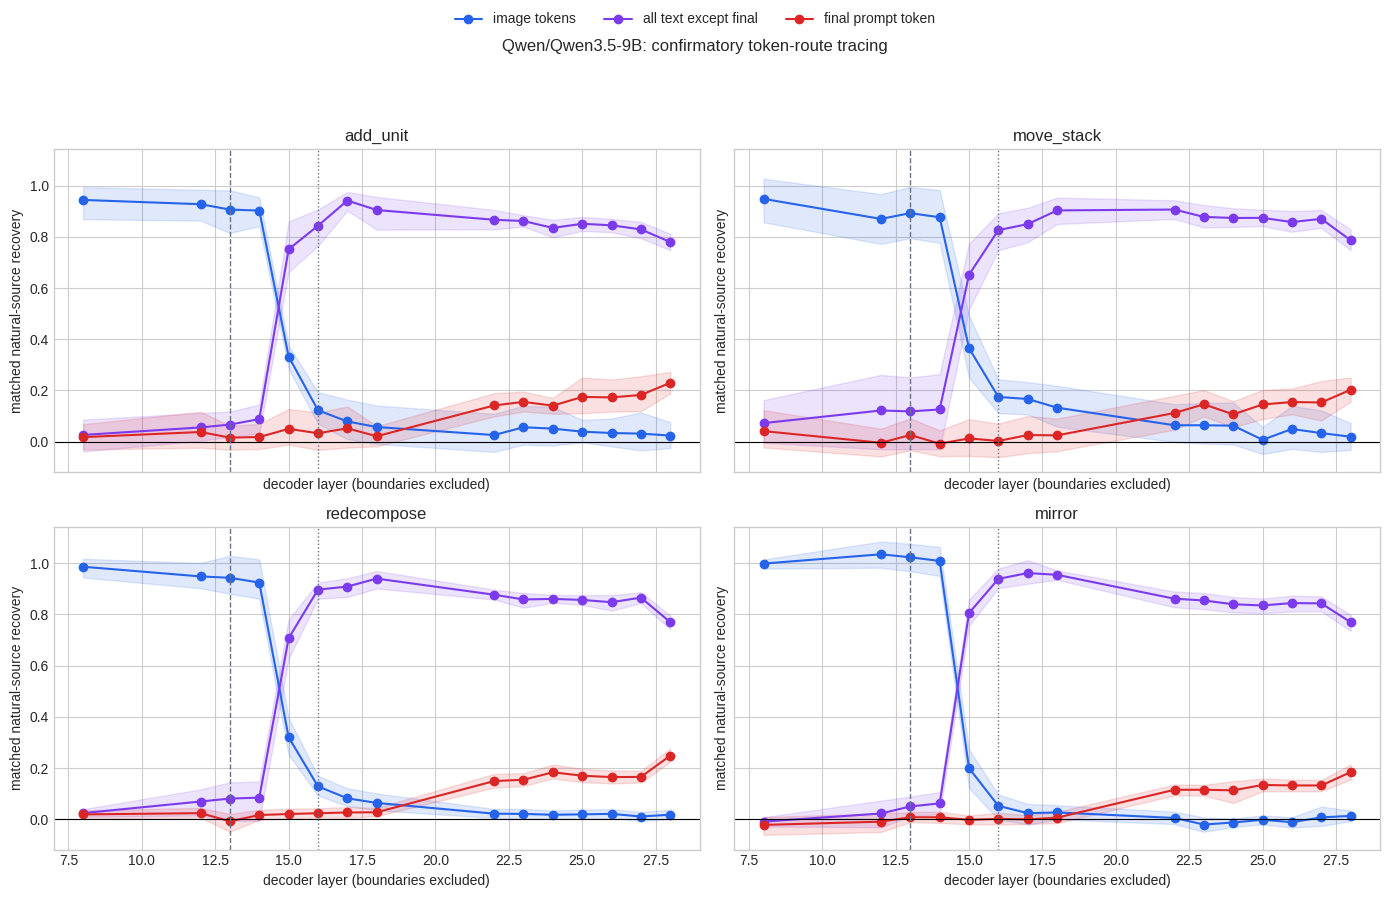

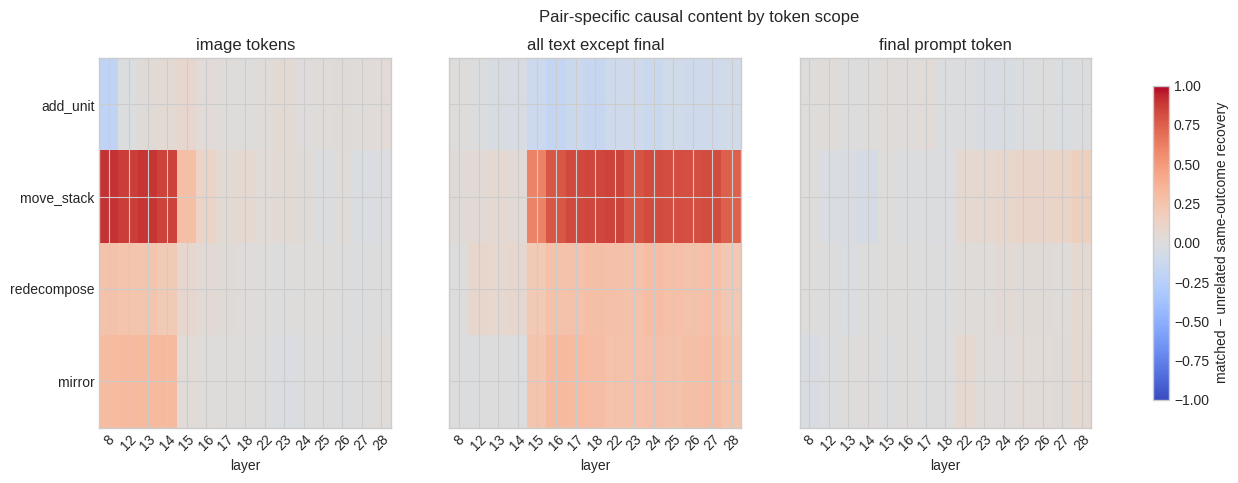

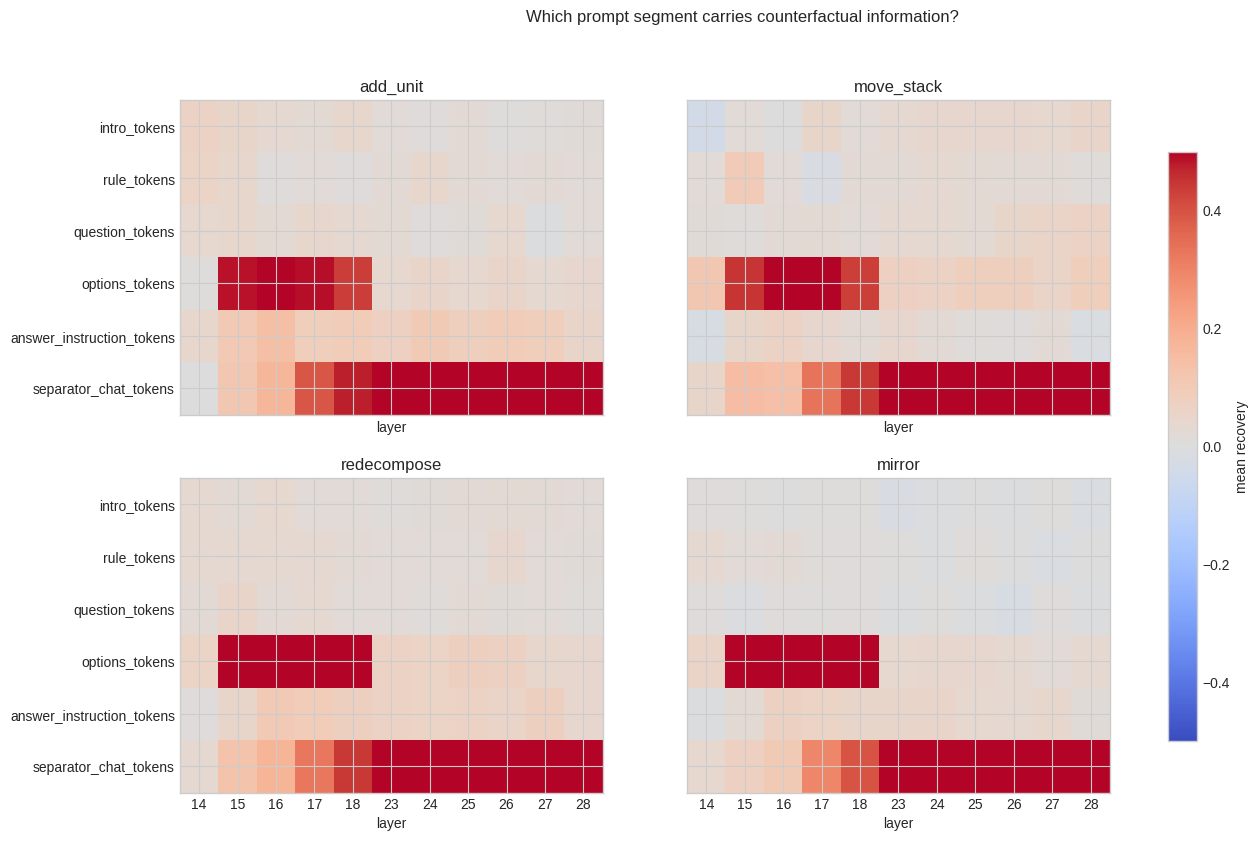

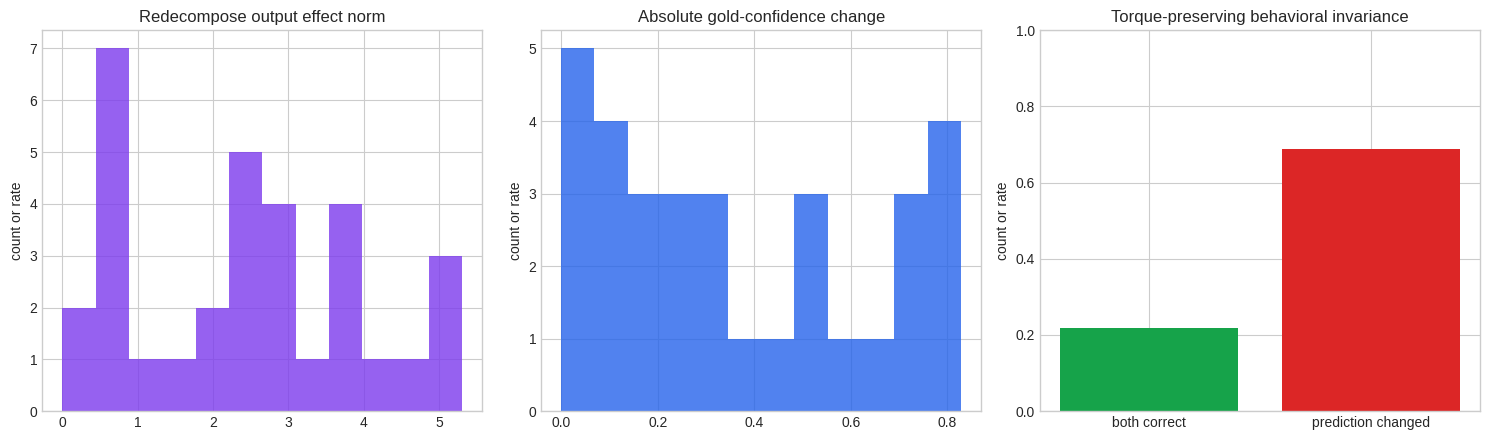

Figures saved to: /content/drive/MyDrive/VisualTorque/results/Qwen__Qwen3.5-9B/counterfactual_causal_tracing_confirmatory_v1/analysis


In [16]:
%%cell_progress 15/16 Save confirmatory figures
cell_stage('Rendering pre-final causal curves and controls')
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
colors = {
    'image_tokens': '#2563eb',
    'all_text_except_final': '#7c3aed',
    'final_prompt_token': '#dc2626',
}
labels = {
    'image_tokens': 'image tokens',
    'all_text_except_final': 'all text except final',
    'final_prompt_token': 'final prompt token',
}
matched = layer_summary[
    (layer_summary['analysis_family'] == 'primary_scope')
    & (layer_summary['donor_type'] == 'matched_source')
]
figure, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for axis, edit_type in zip(axes.flat, EDIT_TYPES):
    subset = matched[
        (matched['edit_type'] == edit_type)
        & matched['layer_index'].isin(INFERENTIAL_LAYERS)
    ]
    for scope in PRIMARY_SCOPES:
        curve = subset[subset['scope'] == scope].sort_values('layer_index')
        axis.plot(
            curve['layer_index'], curve['recovery_mean'], marker='o',
            color=colors[scope], label=labels[scope],
        )
        axis.fill_between(
            curve['layer_index'], curve['recovery_ci_low'],
            curve['recovery_ci_high'], color=colors[scope], alpha=0.14,
        )
    axis.axhline(0, color='black', linewidth=0.8)
    axis.axvline(13, color='#64748b', linestyle='--', linewidth=1)
    axis.axvline(16, color='#64748b', linestyle=':', linewidth=1)
    axis.set_title(edit_type)
    axis.set_xlabel('decoder layer (boundaries excluded)')
    axis.set_ylabel('matched natural-source recovery')
handles, legend_labels = axes.flat[0].get_legend_handles_labels()
figure.legend(
    handles, legend_labels, loc='upper center', ncol=3, frameon=False
)
figure.suptitle(
    f'{MODEL_ID}: confirmatory token-route tracing', y=0.96
)
figure.tight_layout(rect=(0, 0, 1, 0.91))
figure.savefig(
    ANALYSIS_DIR / 'confirmatory_route_by_edit.png',
    dpi=180, bbox_inches='tight',
)
plt.show()

figure, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for axis, scope in zip(axes, PRIMARY_SCOPES):
    subset = gap_frame[
        (gap_frame['scope'] == scope)
        & (gap_frame['control'] == 'unrelated_same_source_outcome')
        & gap_frame['layer_index'].isin(INFERENTIAL_LAYERS)
    ]
    matrix = subset.pivot(
        index='edit_type', columns='layer_index', values='mean'
    ).reindex(index=EDIT_TYPES, columns=INFERENTIAL_LAYERS)
    image = axis.imshow(
        matrix.to_numpy(), aspect='auto', cmap='coolwarm', vmin=-1, vmax=1
    )
    axis.set_xticks(range(len(INFERENTIAL_LAYERS)), INFERENTIAL_LAYERS)
    axis.tick_params(axis='x', rotation=45)
    axis.set_yticks(range(len(EDIT_TYPES)), EDIT_TYPES)
    axis.set_title(labels[scope])
    axis.set_xlabel('layer')
figure.colorbar(
    image, ax=axes, label='matched − unrelated same-outcome recovery',
    shrink=0.85,
)
figure.suptitle('Pair-specific causal content by token scope')
figure.savefig(
    ANALYSIS_DIR / 'matched_control_gap_heatmaps.png',
    dpi=180, bbox_inches='tight',
)
plt.show()

figure, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, sharey=True)
segment_order = list(TEXT_SEGMENT_SCOPES)
for axis, edit_type in zip(axes.flat, EDIT_TYPES):
    subset = localization_summary[
        localization_summary['edit_type'] == edit_type
    ]
    matrix = subset.pivot(
        index='scope', columns='layer_index', values='recovery_mean'
    ).reindex(index=segment_order, columns=TEXT_LOCALIZATION_LAYERS)
    image = axis.imshow(
        matrix.to_numpy(), aspect='auto', cmap='coolwarm', vmin=-0.5, vmax=0.5
    )
    axis.set_xticks(
        range(len(TEXT_LOCALIZATION_LAYERS)), TEXT_LOCALIZATION_LAYERS
    )
    axis.set_yticks(range(len(segment_order)), segment_order)
    axis.set_title(edit_type)
    axis.set_xlabel('layer')
figure.colorbar(image, ax=axes, label='mean recovery', shrink=0.85)
figure.suptitle('Which prompt segment carries counterfactual information?')
figure.savefig(
    ANALYSIS_DIR / 'text_segment_localization.png',
    dpi=180, bbox_inches='tight',
)
plt.show()

figure, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].hist(
    redecompose_frame['natural_effect_norm'], bins=12,
    color='#7c3aed', alpha=0.8,
)
axes[0].set_title('Redecompose output effect norm')
axes[1].hist(
    redecompose_frame['absolute_gold_probability_change'], bins=12,
    color='#2563eb', alpha=0.8,
)
axes[1].set_title('Absolute gold-confidence change')
axes[2].bar(
    ['both correct', 'prediction changed'],
    [
        redecompose_summary['both_correct_rate'],
        redecompose_summary['prediction_change_rate'],
    ],
    color=['#16a34a', '#dc2626'],
)
axes[2].set_ylim(0, 1)
axes[2].set_title('Torque-preserving behavioral invariance')
for axis in axes:
    axis.set_ylabel('count or rate')
figure.tight_layout()
figure.savefig(
    ANALYSIS_DIR / 'redecompose_invariance.png',
    dpi=180, bbox_inches='tight',
)
plt.show()
print('Figures saved to:', ANALYSIS_DIR)


In [17]:
%%cell_progress 16/16 Write the confirmatory mechanistic report
cell_stage('Writing frozen decisions without using boundary layers')
report_lines = [
    '# Confirmatory counterfactual causal-tracing report',
    '',
    f'- Model: `{MODEL_ID}`',
    f'- Revision: `{MODEL_REVISION}`',
    f'- Pairs: {len(pair_manifest)} ({PAIRS_PER_EDIT} per edit family)',
    f'- Inferential layers: {list(INFERENTIAL_LAYERS)}',
    '- Layers 0 and 31 were retained only as implementation ceilings.',
    '',
    '## Frozen hypothesis decisions',
    '',
]
for _, row in hypothesis_frame.iterrows():
    state = (
        'NOT TESTABLE' if pd.isna(row['passed'])
        else ('PASS' if bool(row['passed']) else 'FAIL')
    )
    layer_suffix = (
        f"; best layer {int(row['best_layer'])}"
        if 'best_layer' in row and pd.notna(row.get('best_layer'))
        else ''
    )
    report_lines.append(
        f"- **{row['edit_type']} / {row['hypothesis']}: {state}.** "
        f"Estimate {row['mean']:.3f} "
        f"[{row['ci_low']:.3f}, {row['ci_high']:.3f}], "
        f"n={int(row['n_pairs'])}{layer_suffix}."
    )

report_lines.extend([
    '',
    '## Torque-preserving redecomposition',
    '',
    f"- Both-endpoint accuracy: {redecompose_summary['both_correct_rate']:.3f}.",
    f"- Prediction-change rate: {redecompose_summary['prediction_change_rate']:.3f}.",
    f"- Mean semantic-output effect norm: "
    f"{redecompose_summary['mean_natural_effect_norm']:.3f}.",
    f"- Mean absolute gold-confidence change: "
    f"{redecompose_summary['mean_absolute_gold_probability_change']:.3f}.",
    '',
    'A large output effect with a low prediction-change rate means that torque and '
    'outcome may be behaviorally preserved while confidence remains factorization-'
    'sensitive. A high prediction-change rate is stronger evidence of incomplete '
    'physical abstraction. Neither result alone identifies the responsible visual '
    'shortcut.',
    '',
    '## Text-token localization',
    '',
])
for edit_type in EDIT_TYPES:
    subset = localization_summary[
        localization_summary['edit_type'] == edit_type
    ]
    valid_subset = subset.dropna(subset=['recovery_mean'])
    if len(valid_subset):
        best = valid_subset.loc[valid_subset['recovery_mean'].idxmax()]
        report_lines.append(
            f"- {edit_type}: largest individual segment recovery is "
            f"{best['scope']} at layer {int(best['layer_index'])}, "
            f"mean {best['recovery_mean']:.3f} "
            f"[{best['recovery_ci_low']:.3f}, "
            f"{best['recovery_ci_high']:.3f}]."
        )

report_lines.extend([
    '',
    '## Strategy-group rule',
    '',
    'Only strata with at least eight counterfactual pairs are reportable. Smaller '
    'strata remain descriptive and cannot support strategy-switching claims.',
    '',
])
reportable = strategy_frame[strategy_frame['reportable']]
if len(reportable):
    for keys, group in reportable.groupby(['edit_type', 'strategy_group']):
        report_lines.append(
            f"- {keys[0]} / {keys[1]}: reportable across "
            f"{group['scope'].nunique()} scopes and "
            f"{group['layer_index'].nunique()} key layers."
        )
else:
    report_lines.append('- No strategy stratum reached the frozen n ≥ 8 threshold.')

h1_h4 = hypothesis_frame[
    hypothesis_frame['hypothesis'].isin([
        'H1_early_visual_carrier', 'H2_middle_text_handoff',
        'H3_pair_specific_text_path', 'H4_no_early_final_bottleneck',
    ])
]
core_pass_count = int((h1_h4['passed'] == True).sum())
core_test_count = int(h1_h4['passed'].notna().sum())
route_confirmed = core_pass_count >= int(np.ceil(0.75 * core_test_count))
report_lines.extend([
    '',
    '## Confirmatory conclusion and next experiment',
    '',
    f"- Core route tests passed: {core_pass_count}/{core_test_count}.",
    f"- Three-stage token-route confirmation: "
    f"{'SUPPORTED' if route_confirmed else 'NOT YET SUPPORTED'}.",
    '',
])
if route_confirmed:
    report_lines.extend([
        'The next notebook should perform component-level path patching at the '
        'confirmed handoff layers (attention outputs versus MLP outputs, then heads) '
        'and at the strongest pre-final answer-commitment layers. It should preserve '
        'the same pair manifest and matched/unrelated controls.',
    ])
else:
    report_lines.extend([
        'Do not proceed to individual-head claims. First inspect failed hypotheses, '
        'token-segment coverage, edit-specific timing, and natural-effect stability. '
        'Revise the causal route rather than selecting favorable layers post hoc.',
    ])
report_lines.extend([
    '',
    '## Limits',
    '',
    protocol_identity['interpretation_limit'],
    '',
])

report_path = ANALYSIS_DIR / 'confirmatory_causal_tracing_report.md'
report_path.write_text('\n'.join(report_lines), encoding='utf-8')
decision_summary = {
    'model_id': MODEL_ID,
    'resolved_revision': MODEL_REVISION,
    'pairs': len(pair_manifest),
    'core_route_pass_count': core_pass_count,
    'core_route_test_count': core_test_count,
    'three_stage_route_supported': route_confirmed,
    'redecompose_summary': redecompose_summary,
    'report_path': str(report_path),
    'next_experiment': (
        'component-level attention-versus-MLP path patching on frozen handoff layers'
        if route_confirmed else
        'diagnose failed token-route hypotheses before component decomposition'
    ),
}
write_json_atomic(
    ANALYSIS_DIR / 'confirmatory_decision_summary.json',
    decision_summary,
)
print(report_path.read_text(encoding='utf-8'))
print('Completed confirmatory Qwen tracing.')


Write the confirmatory mechanistic report:  94%|#########3| 15/16 [00:00<?, ?cell/s]

# Confirmatory counterfactual causal-tracing report

- Model: `Qwen/Qwen3.5-9B`
- Revision: `c202236235762e1c871ad0ccb60c8ee5ba337b9a`
- Pairs: 128 (32 per edit family)
- Inferential layers: [8, 12, 13, 14, 15, 16, 17, 18, 22, 23, 24, 25, 26, 27, 28]
- Layers 0 and 31 were retained only as implementation ceilings.

## Frozen hypothesis decisions

- **add_unit / H1_early_visual_carrier: PASS.** Estimate 0.840 [0.721, 0.949], n=32.
- **add_unit / H2_middle_text_handoff: PASS.** Estimate 0.721 [0.580, 0.824], n=32.
- **add_unit / H3_pair_specific_text_path: FAIL.** Estimate -0.178 [-0.576, 0.211], n=32.
- **add_unit / H4_no_early_final_bottleneck: PASS.** Estimate 0.016 [-0.032, 0.063], n=32.
- **add_unit / H5_prefinal_answer_commitment: PASS.** Estimate 0.107 [0.033, 0.171], n=32; best layer 23.
- **move_stack / H1_early_visual_carrier: PASS.** Estimate 0.775 [0.554, 1.015], n=32.
- **move_stack / H2_middle_text_handoff: PASS.** Estimate 0.652 [0.533, 0.760], n=32.
- **move_stack / H3_pa